# 05 - Overview plots

A few plots of the clean data (124 cells) before any modelling. Everything here uses `data/cells_clean.csv` and `data/cycles_clean.parquet` from notebook 04.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cells = pd.read_csv("../data/cells_clean.csv")
cycles = pd.read_parquet("../data/cycles_clean.parquet")
life = cells.set_index("cell_id")["cycle_life"]
print(len(cells), "cells,", len(cycles), "cycles")

124 cells, 99238 cycles


## Capacity fade for all cells

Colour = cycle life. Short-lived cells (dark) drop early, long-lived ones (light) stay flat for longer.

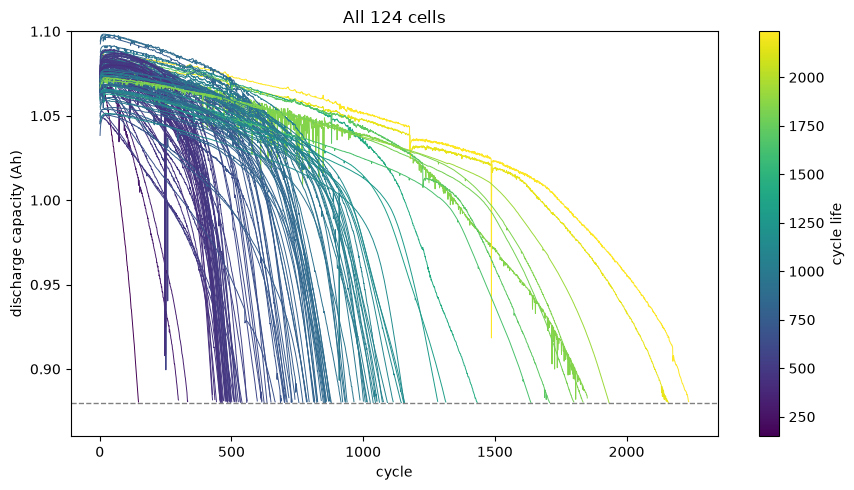

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.get_cmap("viridis")
norm = plt.Normalize(life.min(), life.max())
for cell, d in cycles.groupby("cell_id"):
    ax.plot(d["cycle"], d["q_discharge"], color=cmap(norm(life[cell])), linewidth=0.7)
ax.axhline(0.88, color="grey", linestyle="--", linewidth=1)
ax.set_ylim(0.86, 1.1)
ax.set_xlabel("cycle")
ax.set_ylabel("discharge capacity (Ah)")
ax.set_title("All 124 cells")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="cycle life")
plt.tight_layout()
plt.savefig("../reports/figures/capacity_all_cells.png", dpi=120)
plt.show()

## Six cells across the range

Picked by cycle life: the shortest, the longest, and four in between (10th, 30th, 70th, 90th percentile).

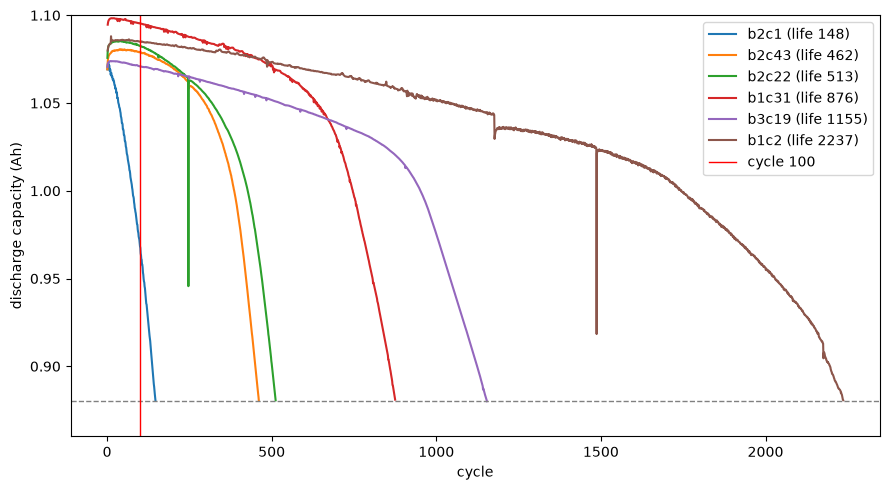

In [3]:
order = life.sort_values()
picks = [order.index[0]] + [order.index[int(p * (len(order) - 1))] for p in [0.1, 0.3, 0.7, 0.9]] + [order.index[-1]]

fig, ax = plt.subplots(figsize=(9, 5))
for cell in picks:
    d = cycles[cycles["cell_id"] == cell]
    ax.plot(d["cycle"], d["q_discharge"], label=f"{cell} (life {life[cell]:.0f})")
ax.axhline(0.88, color="grey", linestyle="--", linewidth=1)
ax.axvline(100, color="red", linewidth=1, label="cycle 100")
ax.set_ylim(0.86, 1.1)
ax.set_xlabel("cycle")
ax.set_ylabel("discharge capacity (Ah)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/capacity_six_cells.png", dpi=120)
plt.show()

## Cycle life per split

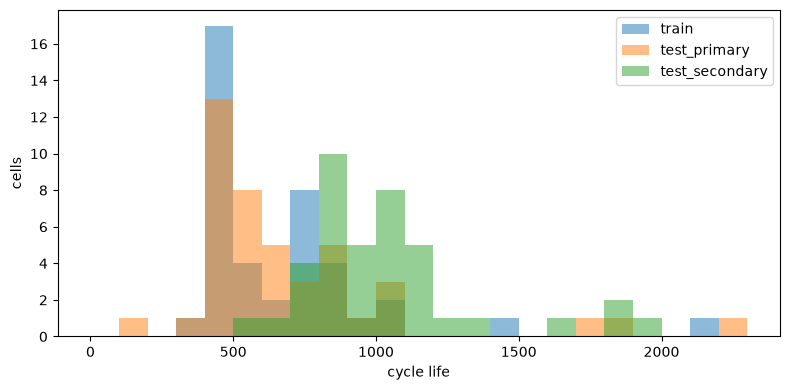

,count,min,median,max
split,,,,
test_primary,43,148.0,561.0,2237.0
test_secondary,40,541.0,964.5,1935.0
train,41,300.0,527.0,2160.0


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 2400, 100)
for split in ["train", "test_primary", "test_secondary"]:
    ax.hist(cells.loc[cells["split"] == split, "cycle_life"], bins=bins, alpha=0.5, label=split)
ax.set_xlabel("cycle life")
ax.set_ylabel("cells")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/cycle_life_hist.png", dpi=120)
plt.show()

cells.groupby("split")["cycle_life"].agg(["count", "min", "median", "max"])

## Can you see the lifetime at cycle 100?

This is the question the whole project is about. The simplest idea is to look at capacity: does a cell that has lost more capacity by cycle 100 die sooner?

In [5]:
q = cycles.pivot(index="cell_id", columns="cycle", values="q_discharge")
early = pd.DataFrame({
    "q2": q[2],
    "q100": q[100],
    "fade_2_100": q[2] - q[100],
    "log_life": np.log10(life),
}).dropna()

for col in ["q2", "q100", "fade_2_100"]:
    r = np.corrcoef(early[col], early["log_life"])[0, 1]
    print(f"correlation of {col} with log10(cycle life): {r:.2f}")

correlation of q2 with log10(cycle life): -0.06
correlation of q100 with log10(cycle life): 0.27
correlation of fade_2_100 with log10(cycle life): -0.41


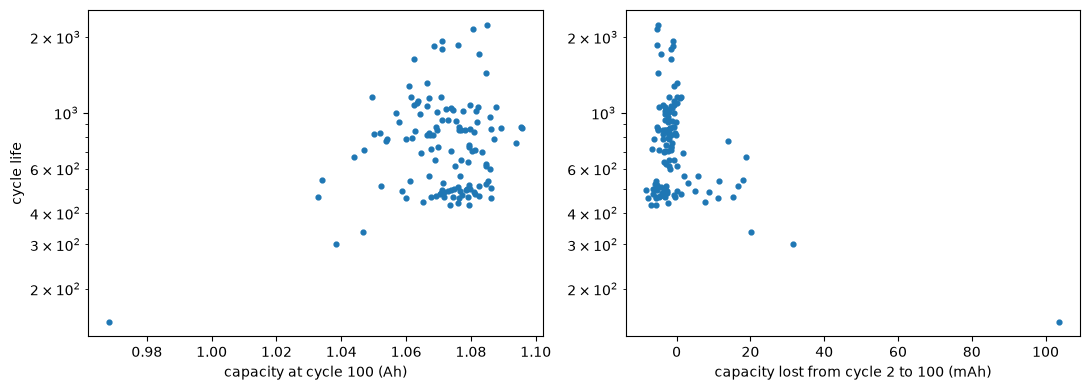

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(early["q100"], 10 ** early["log_life"], s=12)
axes[0].set_xlabel("capacity at cycle 100 (Ah)")
axes[0].set_ylabel("cycle life")
axes[0].set_yscale("log")
axes[1].scatter(early["fade_2_100"] * 1000, 10 ** early["log_life"], s=12)
axes[1].set_xlabel("capacity lost from cycle 2 to 100 (mAh)")
axes[1].set_yscale("log")
plt.tight_layout()
plt.savefig("../reports/figures/early_capacity_vs_life.png", dpi=120)
plt.show()

In [7]:
# how much of that correlation comes from the 3 cells that die before cycle 350?
rest = early[10 ** early["log_life"] > 350]
r = np.corrcoef(rest["fade_2_100"], rest["log_life"])[0, 1]
print(f"without them ({len(rest)} cells): {r:.2f}")
print(f"cells with more capacity at cycle 100 than at cycle 2: {(early['fade_2_100'] < 0).mean():.0%}")

without them (121 cells): -0.14
cells with more capacity at cycle 100 than at cycle 2: 81%


## Notes

- The all-cells plot shows the shape every cell follows: a long, almost flat stretch, then a "knee" where capacity falls fast. Where the knee happens is what sets the lifetime, from about 150 to 2,240 cycles.
- At cycle 100 (red line in the six-cell plot) the cells look almost the same. Only b2c1, which dies at 148, has clearly started to drop.
- Capacity alone says very little at cycle 100. The correlation with log cycle life is 0.27 for the capacity at cycle 100, and -0.41 for the capacity lost between cycle 2 and 100. That -0.41 comes almost entirely from the three cells that die before cycle 350: without them it drops to -0.14.
- 81% of the cells actually have more capacity at cycle 100 than at cycle 2. Capacity rises a little in the first cycles before it starts to fade, so "how much capacity was lost so far" isn't even the right question this early.
- This is the paper's main point. Lifetime has to come from something finer than total capacity, which is why Stage 2 looks at how the whole discharge curve changes between cycle 10 and 100 (ΔQ(V)).
- The secondary test set (batch 3) sits more to the right of the histogram: median 965 cycles against 527 in train. Train has only a few cells above 1,500 cycles.
- Some single-cycle dips are still in the data (e.g. b2c22 around cycle 250, b1c2 around 1,490). They're one bad measurement each and come back the next cycle. They're all after cycle 100, so they don't touch the features.